# Лабораторная работа 4.2. Краевая задача для ОДУ второго порядка

**Вариант 7.** Решить краевую задачу методом стрельбы и конечно-разностным методом:

$$(2x + 1)\,y'' + 4x\,y' - 4y = 0,\qquad y'(0) = -1,\qquad y'(1) + 2\,y(1) = 3 .$$

In [1]:
import json
import math
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.figsize"] = (9, 5.5)
plt.rcParams["figure.dpi"] = 110

DATA_DIR = "data"

### Вспомогательные функции: чтение данных и оформление вывода

In [2]:
def read_data(name: str) -> dict:
    """Читает JSON-файл с исходными данными."""
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        raise FileNotFoundError(f"файл '{path}' не найден: положите папку data рядом с ноутбуком")
    with open(path, encoding="utf-8") as file:
        return json.load(file)


def scalar(data: dict, key: str) -> float:
    """Читает одно вещественное число по ключу."""
    if key not in data:
        raise ValueError(f"в исходных данных нет ключа '{key}'")
    return float(data[key])


def number(value: float, precision: int = 6) -> str:
    """Число в едином формате; машинный нуль печатается как 0."""
    value = float(value)
    if abs(value) < 0.5 * 10 ** (-precision):
        value = 0.0
    return f"{value:.{precision}f}"


def table(rows: list[list], headers: list[str], title: str | None = None) -> None:
    """Печатает таблицу (pandas используется только для оформления)."""
    if title:
        print(title)
    display(pd.DataFrame(rows, columns=headers).style.hide(axis="index"))


def check(title: str, deviation: float, tolerance: float = 1e-8) -> None:
    """Печатает вердикт проверки по наибольшему отклонению."""
    verdict = "ВЫПОЛНЕНО" if deviation <= tolerance else "НЕ ВЫПОЛНЕНО"
    print(f"  {title}: макс. отклонение = {deviation:.3e}  ->  {verdict}")

In [3]:
from ode import grid_of, runge_kutta, runge_romberg 
from thomas import solve as thomas_solve          

### Правая часть, точное решение и краевые условия

In [4]:
LEFT_VALUE = -1.0      # y'(0) = -1
RIGHT_VALUE = 3.0      # y'(1) + 2*y(1) = 3
RIGHT_WEIGHT = 2.0     # коэффициент при y(1) в правом условии


def rhs(x: float, u: np.ndarray) -> np.ndarray:
    """Правая часть системы: u = (y, z), z = y';  y'' = (4y - 4x*z)/(2x + 1)."""
    y, z = u
    return np.array([z, (4.0 * y - 4.0 * x * z) / (2.0 * x + 1.0)])


def exact(x: float) -> float:
    """Точное решение краевой задачи."""
    return x + math.exp(-2.0 * x)


def residual(values: np.ndarray) -> float:
    """Невязка правого краевого условия: Phi = y'(b) + 2*y(b) - 3."""
    return float(values[1] + RIGHT_WEIGHT * values[0] - RIGHT_VALUE)


def max_error(x: np.ndarray, y: np.ndarray) -> float:
    """Наибольшее отклонение численного решения от точного."""
    return float(max(abs(y[k] - exact(x[k])) for k in range(len(x))))

### Метод стрельбы

In [5]:
def shooting(left: float, right: float, step: float, eta0: float, eta1: float,
             epsilon: float, max_iterations: int):
    """Подбор eta = y(a) методом секущих по невязке правого краевого условия."""
    history = []
    previous, current = eta0, eta1
    previous_residual = residual(runge_kutta(rhs, left, right, step,
                                             np.array([previous, LEFT_VALUE]))[1][-1])
    history.append((0, previous, previous_residual))

    for k in range(1, max_iterations + 1):
        x, values = runge_kutta(rhs, left, right, step, np.array([current, LEFT_VALUE]))
        current_residual = residual(values[-1])
        history.append((k, current, current_residual))
        if abs(current_residual) <= epsilon:
            return x, values[:, 0], values[:, 1], history
        if current_residual == previous_residual:
            raise ValueError("метод секущих остановился: невязки двух приближений совпали")
        following = current - current_residual * (current - previous) / (current_residual
                                                                         - previous_residual)
        previous, previous_residual = current, current_residual
        current = following

    raise ValueError(f"метод стрельбы не сошёлся за {max_iterations} итераций")

### Конечно-разностный метод

In [6]:
def difference_coefficients(x: np.ndarray, step: float):
    """Коэффициенты разностной схемы во внутренних узлах."""
    a = (2.0 * x + 1.0) / step ** 2 - 2.0 * x / step
    b = -2.0 * (2.0 * x + 1.0) / step ** 2 - 4.0
    c = (2.0 * x + 1.0) / step ** 2 + 2.0 * x / step
    return a, b, c, np.zeros(len(x))


def finite_difference(left: float, right: float, step: float):
    """Трёхдиагональная система разностной схемы, решаемая прогонкой."""
    x = grid_of(left, right, step)
    n = len(x) - 1
    if n < 3:
        raise ValueError("для разностной схемы нужно не менее трёх шагов сетки")
    a, b, c, d = difference_coefficients(x, step)

    lower, main, upper, rhs_vector = (np.zeros(n + 1) for _ in range(4))
    for i in range(1, n):
        lower[i], main[i], upper[i], rhs_vector[i] = a[i], b[i], c[i], d[i]

    # левое условие y'(a) = -1: (-3y0 + 4y1 - y2)/(2h); y2 исключён через строку i = 1
    main[0] = a[1] - 3.0 * c[1]
    upper[0] = b[1] + 4.0 * c[1]
    rhs_vector[0] = 2.0 * step * LEFT_VALUE * c[1] + d[1]

    # правое условие y'(b) + 2y(b) = 3; y(n-2) исключён через строку i = n-1
    lower[n] = -4.0 * a[n - 1] - b[n - 1]
    main[n] = (3.0 + 2.0 * step * RIGHT_WEIGHT) * a[n - 1] - c[n - 1]
    rhs_vector[n] = 2.0 * step * RIGHT_VALUE * a[n - 1] - d[n - 1]

    return x, thomas_solve(lower, main, upper, rhs_vector)

### Исходные данные

In [7]:
data = read_data("lab4_2.json")
left = scalar(data, "left")
right = scalar(data, "right")
step = scalar(data, "h")
eta0 = scalar(data, "eta0")
eta1 = scalar(data, "eta1")
epsilon = scalar(data, "epsilon")
max_iterations = int(data.get("max_iterations", 50))

print("Уравнение:  (2x + 1)*y'' + 4x*y' - 4y = 0")
print("Краевые условия:  y'(0) = -1   и   y'(1) + 2*y(1) = 3")
print(f"Отрезок: [{left:g}, {right:g}],  шаг h = {step:g},  узлов {len(grid_of(left, right, step))}")
print("Точное решение: y = x + exp(-2x)")
print(f"Параметры метода стрельбы: eta0 = {eta0:g}, eta1 = {eta1:g}, eps = {epsilon}")

Уравнение:  (2x + 1)*y'' + 4x*y' - 4y = 0
Краевые условия:  y'(0) = -1   и   y'(1) + 2*y(1) = 3
Отрезок: [0, 1],  шаг h = 0.1,  узлов 11
Точное решение: y = x + exp(-2x)
Параметры метода стрельбы: eta0 = 0.5, eta1 = 1.5, eps = 1e-10


### Решение методом стрельбы

In [8]:
x_shoot, y_shoot, z_shoot, history = shooting(left, right, step, eta0, eta1,
                                              epsilon, max_iterations)

table([[k, number(eta, 10), f"{value:.3e}"] for k, eta, value in history],
      ["k", "eta_k = y(a)", "Phi(eta_k)"], "Итерации подбора параметра методом секущих")
print(f"Найдено eta = {history[-1][1]:.10f} при точности {epsilon}")
print(f"Точное значение y(a) = {exact(left):.10f}")
print("Задача линейная, поэтому Phi(eta) линейна и метод секущих даёт корень сразу.")
print()

table([[k, number(x_shoot[k], 2), number(y_shoot[k], 8), number(exact(x_shoot[k]), 8),
        f"{abs(y_shoot[k] - exact(x_shoot[k])):.3e}"] for k in range(len(x_shoot))],
      ["k", "x_k", "y_k", "точное y(x_k)", "|y_k - y(x_k)|"], "Решение методом стрельбы")
print(f"  Максимальная погрешность: {max_error(x_shoot, y_shoot):.3e}")

Итерации подбора параметра методом секущих


k,eta_k = y(a),Phi(eta_k)
0,0.5000000000,-3.000e+00
1,1.5000000000,3.000e+00
2,1.0000000000,-4.441e-16


Найдено eta = 1.0000000000 при точности 1e-10
Точное значение y(a) = 1.0000000000
Задача линейная, поэтому Phi(eta) линейна и метод секущих даёт корень сразу.

Решение методом стрельбы


k,x_k,y_k,точное y(x_k),|y_k - y(x_k)|
0,0.00,1.00000000,1.00000000,0.000e+00
1,0.10,0.91873333,0.91873075,2.580e-06
2,0.20,0.87032427,0.87032005,4.225e-06
3,0.30,0.84881682,0.84881164,5.189e-06
4,0.40,0.84933463,0.84932896,5.664e-06
5,0.50,0.86788524,0.86787944,5.797e-06
6,0.60,0.90119991,0.90119421,5.695e-06
7,0.70,0.94660240,0.94659696,5.440e-06
8,0.80,1.00190161,1.00189652,5.090e-06
9,0.90,1.06530358,1.06529889,4.689e-06


  Максимальная погрешность: 5.797e-06


### Решение конечно-разностным методом

In [9]:
x_diff, y_diff = finite_difference(left, right, step)
a_coef, b_coef, c_coef, d_coef = difference_coefficients(x_diff, step)

table([[i, number(x_diff[i], 2), number(a_coef[i], 4), number(b_coef[i], 4),
        number(c_coef[i], 4), number(d_coef[i], 4)] for i in range(1, len(x_diff) - 1)],
      ["i", "x_i", "A_i", "B_i", "C_i", "D_i"],
      "Коэффициенты разностной схемы во внутренних узлах")
print()

table([[k, number(x_diff[k], 2), number(y_diff[k], 8), number(exact(x_diff[k]), 8),
        f"{abs(y_diff[k] - exact(x_diff[k])):.3e}"] for k in range(len(x_diff))],
      ["k", "x_k", "y_k", "точное y(x_k)", "|y_k - y(x_k)|"],
      "Решение конечно-разностным методом")
print(f"  Максимальная погрешность: {max_error(x_diff, y_diff):.3e}")

Коэффициенты разностной схемы во внутренних узлах


i,x_i,A_i,B_i,C_i,D_i
1,0.10,118.0000,-244.0000,122.0000,0.0000
2,0.20,136.0000,-284.0000,144.0000,0.0000
3,0.30,154.0000,-324.0000,166.0000,0.0000
4,0.40,172.0000,-364.0000,188.0000,0.0000
5,0.50,190.0000,-404.0000,210.0000,0.0000
6,0.60,208.0000,-444.0000,232.0000,0.0000
7,0.70,226.0000,-484.0000,254.0000,0.0000
8,0.80,244.0000,-524.0000,276.0000,0.0000
9,0.90,262.0000,-564.0000,298.0000,0.0000



Решение конечно-разностным методом


k,x_k,y_k,точное y(x_k),|y_k - y(x_k)|
0,0.00,1.01158515,1.00000000,1.159e-02
1,0.10,0.92816851,0.91873075,9.438e-03
2,0.20,0.87791860,0.87032005,7.599e-03
3,0.30,0.85484698,0.84881164,6.035e-03
4,0.40,0.85404191,0.84932896,4.713e-03
5,0.50,0.87147646,0.86787944,3.597e-03
6,0.60,0.90385012,0.90119421,2.656e-03
7,0.70,0.94845841,0.94659696,1.861e-03
8,0.80,1.00308561,1.00189652,1.189e-03
9,0.90,1.06591669,1.06529889,6.178e-04


  Максимальная погрешность: 1.159e-02


### Оценка погрешности методом Рунге-Ромберга

In [10]:
x_shoot_half, y_shoot_half, _z, _h = shooting(left, right, step / 2.0, eta0, eta1,
                                              epsilon, max_iterations)
x_diff_half, y_diff_half = finite_difference(left, right, step / 2.0)

results = [
    ("Метод стрельбы", 4, x_shoot, y_shoot, x_shoot_half, y_shoot_half, z_shoot),
    ("Конечно-разностный метод", 2, x_diff, y_diff, x_diff_half, y_diff_half, None),
]

rows = []
for title, order, x, y, x_half, y_half, _z in results:
    refined, estimate = runge_romberg(y, y_half[::2], order)
    exact_values = np.array([exact(point) for point in x])
    rows.append([title, order, f"{max_error(x, y):.3e}", f"{max_error(x_half, y_half):.3e}",
                 f"{float(np.abs(estimate).max()):.3e}",
                 f"{float(np.abs(refined - exact_values).max()):.3e}"])

table(rows, ["метод", "p", "макс.|y(h) - точн|", "макс.|y(h/2) - точн|",
             "оценка Р-Р для h/2", "макс.|Р-Р - точн|"],
      f"Задача решена с шагами h = {step:g} и h/2 = {step / 2:g}")

Задача решена с шагами h = 0.1 и h/2 = 0.05


метод,p,макс.|y(h) - точн|,макс.|y(h/2) - точн|,оценка Р-Р для h/2,макс.|Р-Р - точн|
Метод стрельбы,4,5.797e-06,3.332e-07,3.642e-07,3.101e-08
Конечно-разностный метод,2,1.159e-02,3.123e-03,2.821e-03,3.025e-04


### Сравнение методов и проверка краевых условий

In [11]:
table([[title, order, number(y[0], 8), number(y[-1], 8), f"{max_error(x, y):.3e}"]
       for title, order, x, y, _xh, _yh, _z in results],
      ["метод", "p", "y(a)", "y(b)", "макс. погрешность"], "Сравнение методов")

best = min(results, key=lambda item: max_error(item[2], item[3]))
print(f"Наиболее точный метод: {best[0]}.")
print()

for title, _order, x, y, _xh, _yh, derivative in results:
    if derivative is None:
        left_derivative = (-3.0 * y[0] + 4.0 * y[1] - y[2]) / (2.0 * step)
        right_derivative = (3.0 * y[-1] - 4.0 * y[-2] + y[-3]) / (2.0 * step)
        note = "производные взяты разностной аппроксимацией второго порядка"
    else:
        left_derivative, right_derivative = derivative[0], derivative[-1]
        note = "производная вычислена вместе с решением системы"
    print(f"{title} ({note}):")
    check("  y'(0) = -1", abs(left_derivative - LEFT_VALUE), 1e-8)
    check("  y'(1) + 2*y(1) = 3",
          abs(right_derivative + RIGHT_WEIGHT * y[-1] - RIGHT_VALUE), 1e-8)

Сравнение методов


метод,p,y(a),y(b),макс. погрешность
Метод стрельбы,4,1.00000000,1.13533955,5.797e-06
Конечно-разностный метод,2,1.01158515,1.13546504,1.159e-02


Наиболее точный метод: Метод стрельбы.

Метод стрельбы (производная вычислена вместе с решением системы):
    y'(0) = -1: макс. отклонение = 0.000e+00  ->  ВЫПОЛНЕНО
    y'(1) + 2*y(1) = 3: макс. отклонение = 4.441e-16  ->  ВЫПОЛНЕНО
Конечно-разностный метод (производные взяты разностной аппроксимацией второго порядка):
    y'(0) = -1: макс. отклонение = 2.442e-15  ->  ВЫПОЛНЕНО
    y'(1) + 2*y(1) = 3: макс. отклонение = 3.553e-15  ->  ВЫПОЛНЕНО


### Графики

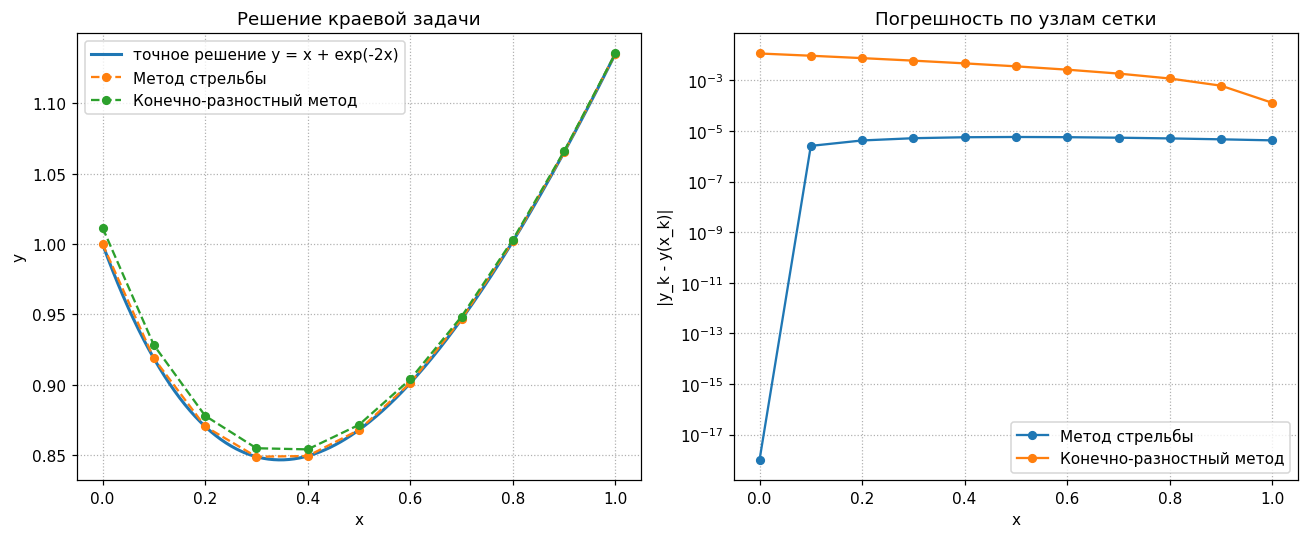

In [12]:
dense = np.linspace(left, right, 400)
figure, (axes_left, axes_right) = plt.subplots(1, 2, figsize=(12, 5))

axes_left.plot(dense, [exact(point) for point in dense], linewidth=2,
               label="точное решение y = x + exp(-2x)")
for title, _order, x, y, _xh, _yh, _z in results:
    axes_left.plot(x, y, "o--", markersize=5, label=title)
axes_left.set_title("Решение краевой задачи")
axes_left.set_xlabel("x"); axes_left.set_ylabel("y")

for title, _order, x, y, _xh, _yh, _z in results:
    errors = [max(abs(y[k] - exact(x[k])), 1e-18) for k in range(len(x))]
    axes_right.semilogy(x, errors, "o-", markersize=5, label=title)
axes_right.set_title("Погрешность по узлам сетки")
axes_right.set_xlabel("x"); axes_right.set_ylabel("|y_k - y(x_k)|")

for axes in (axes_left, axes_right):
    axes.grid(True, linestyle=":")
    axes.legend()
figure.tight_layout()
plt.show()